# Hotel Booking Cancellation Prediction

This notebook is the whole project: every step has **code**, a **figure or table**, and a **Decision** cell that explains what we found and why we chose what we did.

| Rubric item | Section |
|---|---|
| 1. Data cleaning and preprocessing | 2, 3 |
| 2. Feature selection | 4 |
| 3. Model selection, training and testing | 5 |
| 4. Meta-classifier | 6 |
| 5. EC2 deployment and testing | 7 (saves the model for the API) |

## 1. Objective
Predict whether a customer will **cancel** their hotel booking (target column: `booking status`).

- Problem type: binary classification (`Canceled` = 1, `Not_Canceled` = 0)
- Final model: a stacking **meta-classifier** built on the 3 best models
- The final model is served by a small FastAPI app on an AWS EC2 instance

# Importing Necessary Libraries

In [58]:
import warnings

warnings.filterwarnings("ignore")

import json
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import cross_val_score, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from xgboost import XGBClassifier

In [59]:
# Running in Google Colab? Uncomment the next two lines and change DATA_PATH to where you uploaded booking.csv
# from google.colab import drive
# drive.mount('/content/drive')

DATA_PATH = "../data/raw/booking.csv"
CLEAN_PATH = "../data/processed/booking_clean.csv"
MODEL_PATH = "../models/stacking_model.joblib"
SAMPLE_PATH = "../sample_requests/predict.json"
REQUIREMENTS_PATH = "../requirements.txt"

for p in [CLEAN_PATH, MODEL_PATH, SAMPLE_PATH, REQUIREMENTS_PATH]:
    Path(p).parent.mkdir(parents=True, exist_ok=True)

In [60]:
RANDOM_STATE = 42

## 2. Dataset column details

In [61]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print("NUMBER OF ROWS AND COLUMNS IN DATASET", df.shape)
df.head()

NUMBER OF ROWS AND COLUMNS IN DATASET (36285, 17)


,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
0,INN00001,1,1,2,5,Meal Plan 1,0,Room_Type 1,224,Offline,0,0,0,88.00,0,10/2/2015,Not_Canceled
1,INN00002,1,0,1,3,Not Selected,0,Room_Type 1,5,Online,0,0,0,106.68,1,11/6/2018,Not_Canceled
2,INN00003,2,1,1,3,Meal Plan 1,0,Room_Type 1,1,Online,0,0,0,50.00,0,2/28/2018,Canceled
3,INN00004,1,0,0,2,Meal Plan 1,0,Room_Type 1,211,Online,0,0,0,100.00,1,5/20/2017,Canceled
4,INN00005,1,0,1,2,Not Selected,0,Room_Type 1,48,Online,0,0,0,77.00,0,4/11/2018,Canceled


In [62]:
# profile for null valuea and data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36285 entries, 0 to 36284
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Booking_ID                36285 non-null  str    
 1   number of adults          36285 non-null  int64  
 2   number of children        36285 non-null  int64  
 3   number of weekend nights  36285 non-null  int64  
 4   number of week nights     36285 non-null  int64  
 5   type of meal              36285 non-null  str    
 6   car parking space         36285 non-null  int64  
 7   room type                 36285 non-null  str    
 8   lead time                 36285 non-null  int64  
 9   market segment type       36285 non-null  str    
 10  repeated                  36285 non-null  int64  
 11  P-C                       36285 non-null  int64  
 12  P-not-C                   36285 non-null  int64  
 13  average price             36285 non-null  float64
 14  special requests 

In [63]:
# Identifying the categorical, binary, and numerical columns so we can process them differently in the pipeline

ID_COL = "Booking_ID"
TARGET = "booking status"
DATE_COL = "date of reservation"

CATEGORICAL_COLS = ["type of meal", "room type", "market segment type"]
BINARY_COLS = ["car parking space", "repeated"]
NUMERIC_COLS = ["number of adults", "number of children", "number of weekend nights",
                "number of week nights", "lead time", "P-C", "P-not-C", "average price", "special requests"]

In [64]:
# summary statistics
print("Numerical columns")
display(df[NUMERIC_COLS].describe().T)

print("Categorical columns")
display(df[CATEGORICAL_COLS + [TARGET]].describe().T)

Numerical columns


,count,mean,std,min,25%,50%,75%,max
number of adults,36285.0,1.844839,0.518813,0.0,2.0,2.00,2.0,4.0
number of children,36285.0,0.105360,0.402704,0.0,0.0,0.00,0.0,10.0
number of weekend nights,36285.0,0.810693,0.870590,0.0,0.0,1.00,2.0,7.0
number of week nights,36285.0,2.204602,1.410946,0.0,1.0,2.00,3.0,17.0
lead time,36285.0,85.239851,85.938796,0.0,17.0,57.00,126.0,443.0
P-C,36285.0,0.023343,0.368281,0.0,0.0,0.00,0.0,13.0
P-not-C,36285.0,0.153369,1.753931,0.0,0.0,0.00,0.0,58.0
average price,36285.0,103.421636,35.086469,0.0,80.3,99.45,120.0,540.0
special requests,36285.0,0.619733,0.786262,0.0,0.0,0.00,1.0,5.0


Categorical columns


,count,unique,top,freq
type of meal,36285,4,Meal Plan 1,27842
room type,36285,7,Room_Type 1,28138
market segment type,36285,5,Online,23221
booking status,36285,2,Not_Canceled,24396


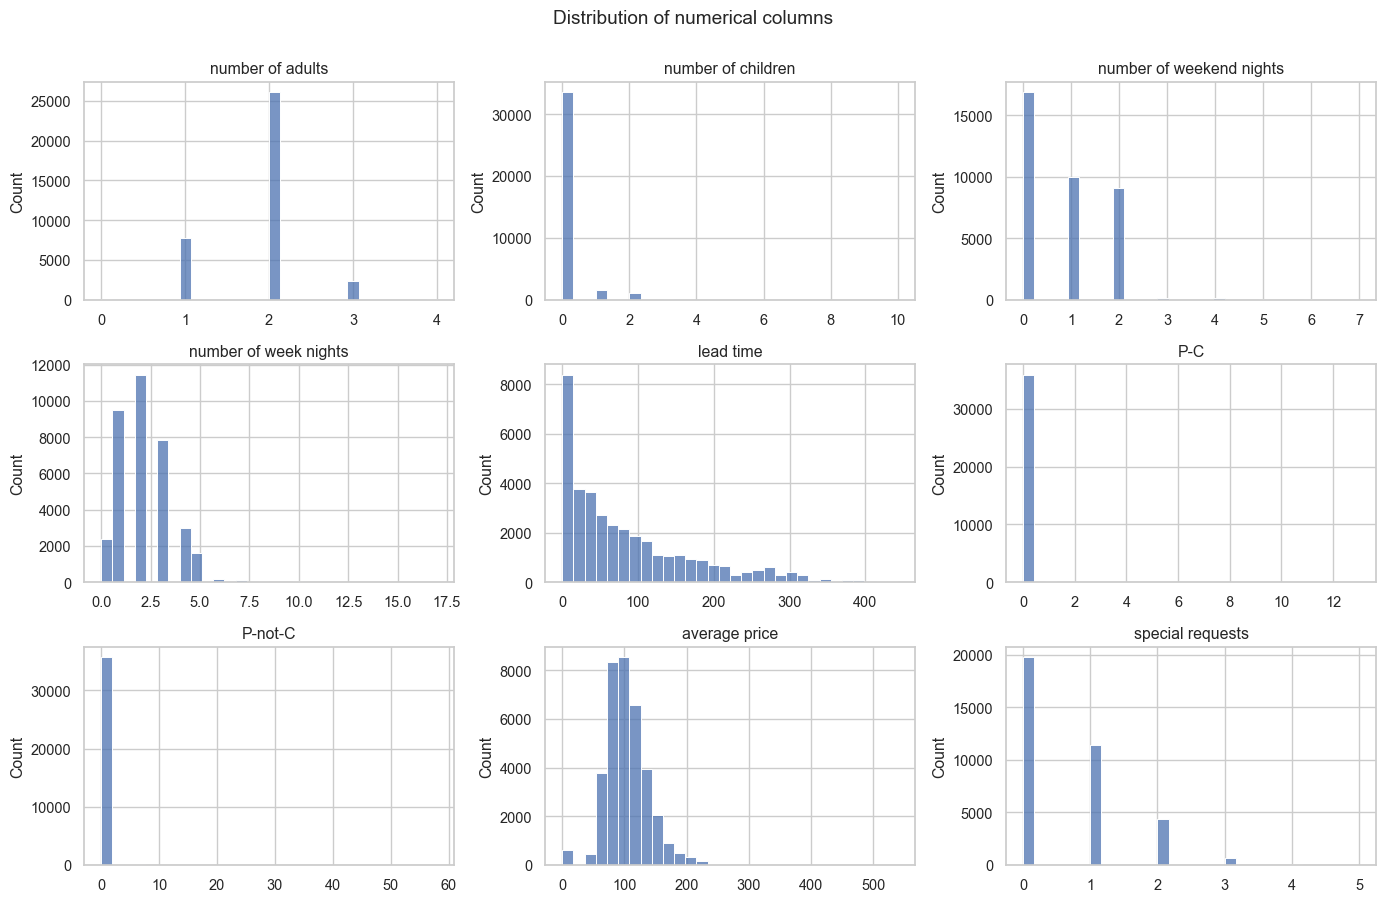

In [65]:
# distribution charts - numerical columns
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distribution of numerical columns", y=1.0)
plt.tight_layout()
plt.show()

**Distribution of numerical columns**

- **number of adults:** Almost every booking is for 2 adults, then 1 adult and 3 adults. Values range from 0 to 4, meaning a handful of bookings list no adults. The shape is concentrated around 2, with no real tail.
- **number of children:** Heavily right-skewed. Most bookings have no children. A few extreme values reach up to 10 children.
- **number of weekend nights:** Takes only the values 0, 1 and 2. Larger values up to 7 are very rare. This is a discrete distribution with a mild right skew.
- **number of week nights:** Peaks at 2 nights, followed by 1 night and 3 nights. Most stays are 1 to 4 weeknights. There is a thin right tail up to 17 nights.
- **lead time:** Strongly right-skewed. Many bookings are made at the last minute, and the counts fall steadily as the lead time grows. The median is 57 days but the mean is 85, which shows the long tail. There were bookings made up to a maximum of 443 days ahead.
- **P-C (previous cancellations):** Almost all values are 0. Only small percentage of guests have a previous cancellation, with a maximum of 13. The distribution is extremely skewed and the column is nearly constant.
- **P-not-C (previous bookings not canceled):** Also dominated by 0. Only about small percentage of guests have earlier completed bookings, and a few loyal guests reach up to 58. Extremely right-skewed.
- **average price:** The closest to a bell shape. It is centered around 100 (median 99, mean 103), and most bookings fall between 60 and 160. There is a small spike at 0 (likely free or complimentary rooms) and a long right tail up to 540.
- **special requests:** Discrete and right-skewed. Most bookings have no special request, Some have 1 or 2, and a few have up to maximum 5.

**Summary:** Only `number of adults` and `average price` are roughly symmetric. Most other numerical columns are right-skewed with a long tail, because most bookings sit at small values and a few extreme ones stretch the range. `P-C` and `P-not-C` are almost entirely zeros, so they carry information for only a small share of guests. The long tails in `lead time`, `average price` and `P-not-C` are why we look at outliers in section 3.3.

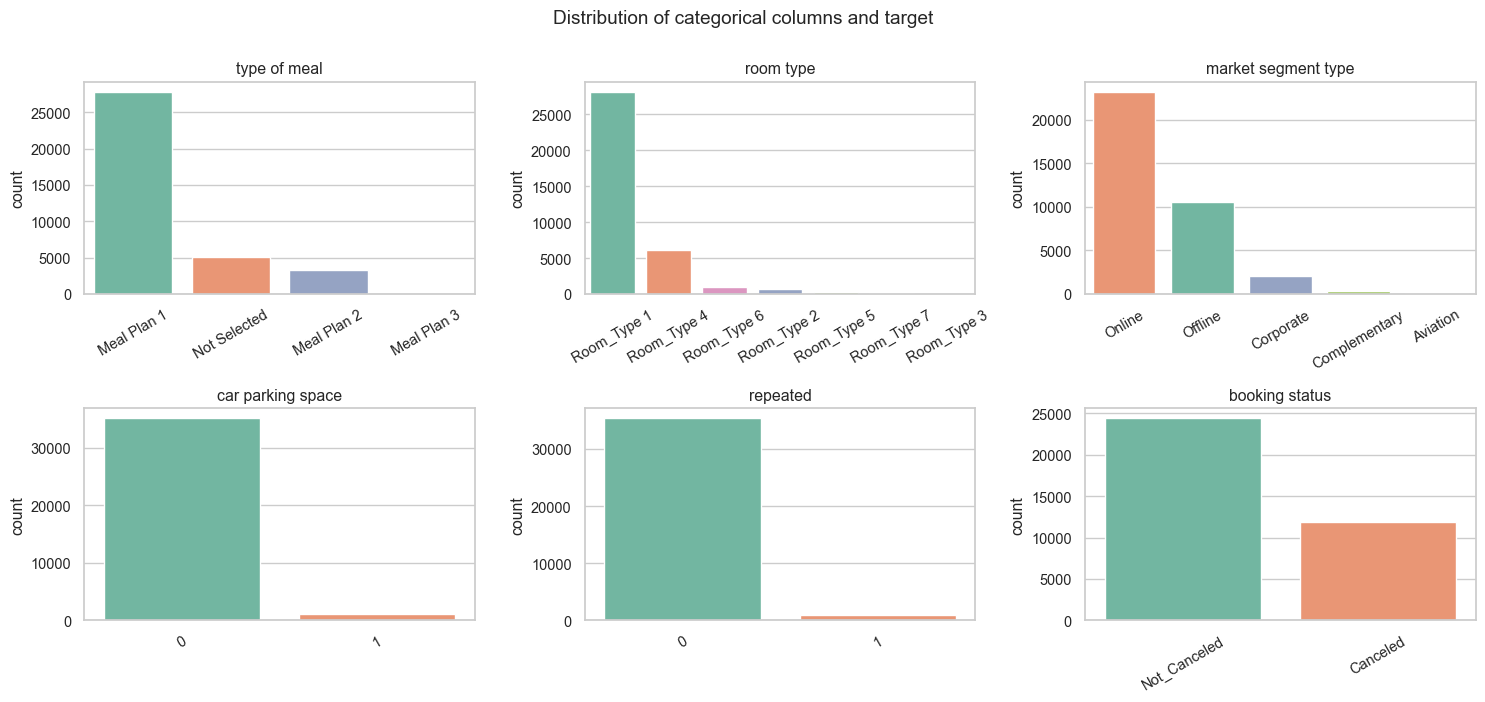

In [66]:
# distribution charts - categorical, binary columns and the target
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, col in zip(axes.ravel(), CATEGORICAL_COLS + BINARY_COLS + [TARGET]):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        hue=col,
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("Distribution of categorical columns and target", y=1.0)
plt.tight_layout()
plt.show()

**Distribution of categorical columns and target**

- **type of meal:** Most guests take Meal Plan 1. "Not Selected" is second, Meal Plan 2 is small, and Meal Plan 3 is almost absent.
- **room type:** Room_Type 1 dominates, Room_Type 4 is a distant second, and the remaining types (2, 3, 5, 6, 7) are very rare.
- **market segment type:** Most bookings come through Online, then Offline. Corporate is small, and Complementary and Aviation are tiny.
- **car parking space:** Almost all bookings do not use a parking space.
- **repeated:** Almost all guests are new guests. Repeated bookings are a very small group.
- **booking status (target):** Not_Canceled is about twice as frequent as Canceled. The classes are imbalanced, but not extremely.

**What this means for our next steps**

1. **Imbalanced target:** The cancel rate is roughly one third, which is a moderate imbalance. A model could look good by mostly predicting "Not_Canceled", so we will use a stratified split and judge models with precision, recall, F1 and ROC-AUC, not accuracy alone (see section 3.5).
2. **Rare categories:** Several categories (Meal Plan 3, most room types, Complementary, Aviation) have very few bookings, so the model has little to learn from and its predictions for them will be less reliable. We keep them, because they are real values. The encoder is set to ignore unseen categories, so a rare category missing from the training split does not crash the pipeline.
3. **Almost-constant columns:** `car parking space` and `repeated` are dominated by one value. They are likely weak features overall, which we check in the feature selection section. A small group can still be informative, for example returning guests might almost never cancel, so we look at the cancel rate per category (section 3.7) and not only at the counts.
4. **Skewed training data:** The model learns mostly from Online bookings, Room_Type 1 and Meal Plan 1. It may be less accurate for the minority groups, so we keep this in mind when explaining the results.

## 3. Data cleaning and graphs
We keep a log of how many rows each step removes.

In [67]:
cleaning_log = [{"step": "raw data", "rows removed": 0, "rows left": len(df)}]


def log_step(step, df_now):
    left = cleaning_log[-1]["rows left"]
    cleaning_log.append({"step": step, "rows removed": left - len(df_now), "rows left": len(df_now)})

### 3.1 Missing values (blank, NaN)

In [68]:
# finding missing values and blank text values
print(df.isnull().sum())
print("\nblank text values:", int(df.astype(str).apply(lambda c: c.str.strip().eq("")).sum().sum()))

Booking_ID                  0
number of adults            0
number of children          0
number of weekend nights    0
number of week nights       0
type of meal                0
car parking space           0
room type                   0
lead time                   0
market segment type         0
repeated                    0
P-C                         0
P-not-C                     0
average price               0
special requests            0
date of reservation         0
booking status              0
dtype: int64

blank text values: 0


**Decision:** We found no missing values of any kind, the dataset was already cleaned from the get go.

### 3.2 Duplicates

In [69]:
print("duplicate Booking_ID:", df[ID_COL].duplicated().sum())

cols_without_id = [c for c in df.columns if c != ID_COL]  # compare every column except the ID
dup_mask = df.duplicated(subset=cols_without_id, keep="first")
print(f"rows identical to an earlier row (ignoring Booking_ID): {dup_mask.sum()} ({dup_mask.mean():.1%})")

duplicate Booking_ID: 0
rows identical to an earlier row (ignoring Booking_ID): 10276 (28.3%)


In [70]:
print("Example of identical bookings that only differ by Booking_ID:")
display(df[df.duplicated(subset=cols_without_id, keep=False)].sort_values(cols_without_id).head(6))

Example of identical bookings that only differ by Booking_ID:


,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
2997,INN02998,0,2,0,2,Meal Plan 1,0,Room_Type 2,187,Online,0,0,0,86.5,1,7/7/2018,Canceled
14463,INN14464,0,2,0,2,Meal Plan 1,0,Room_Type 2,187,Online,0,0,0,86.5,1,7/7/2018,Canceled
2694,INN02695,0,2,0,3,Meal Plan 1,0,Room_Type 2,40,Online,0,0,0,6.0,1,1/14/2018,Not_Canceled
22193,INN22194,0,2,0,3,Meal Plan 1,0,Room_Type 2,40,Online,0,0,0,6.0,1,1/14/2018,Not_Canceled
17592,INN17593,0,2,2,1,Meal Plan 1,0,Room_Type 2,104,Online,0,0,0,91.6,2,12/25/2018,Not_Canceled
32816,INN32817,0,2,2,1,Meal Plan 1,0,Room_Type 2,104,Online,0,0,0,91.6,2,12/25/2018,Not_Canceled


**Decision:** Booking_ID is unique, but if we removed booking_id we found many rows are identical in every other column. 
- This cannot be a real coincidence as it is very unlikely that different booking happen on the same day with the same lead time and the exact same booking details so it must be an error of some sort.
- Plus, the same row can end up in both train and test, which makes the test score look better than it really is.

-> So we wil remove those duplicate rows

In [71]:
df = df[~dup_mask].reset_index(drop=True)
log_step("duplicate rows", df)
print("rows left:", len(df))

rows left: 26009


### 3.3 Outliers

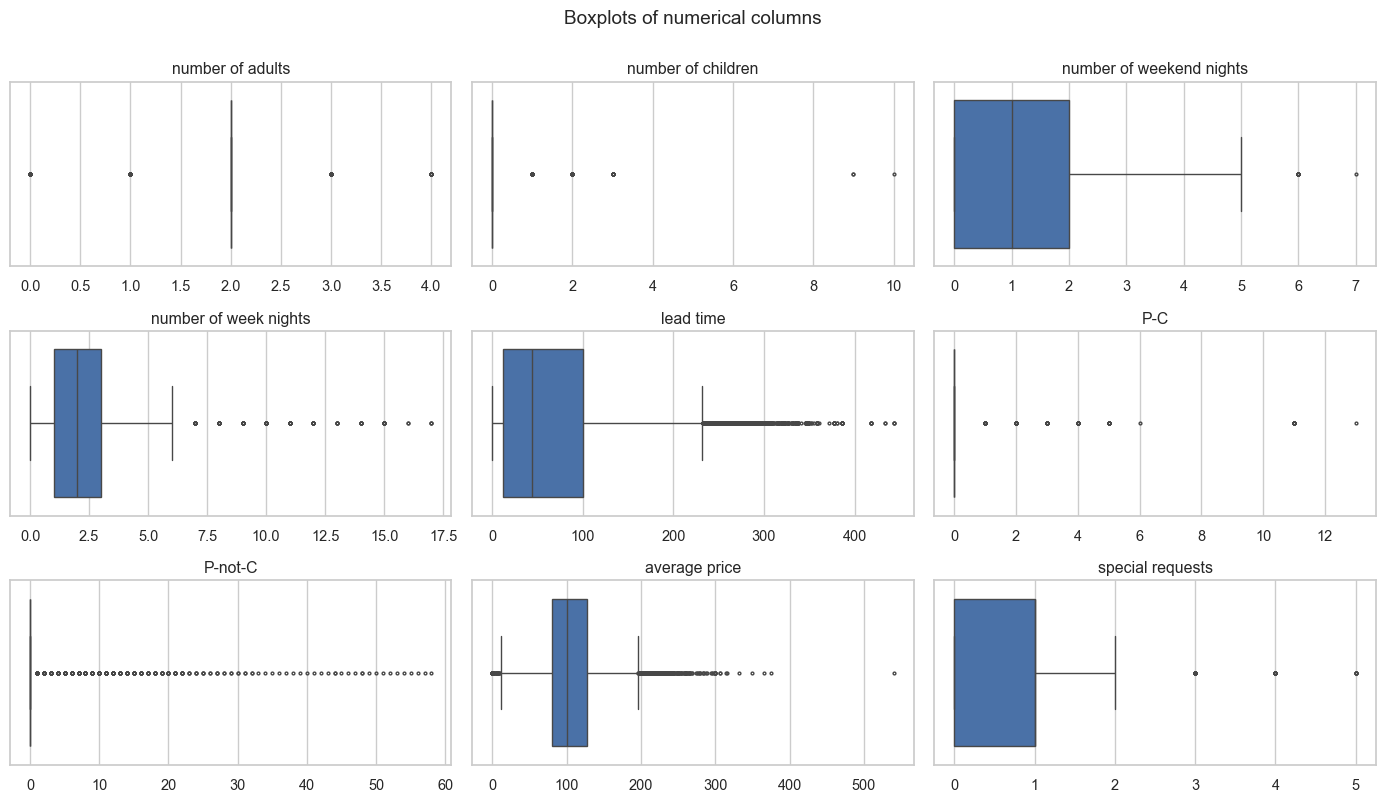

In [72]:
fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    sns.boxplot(x=df[col], ax=ax, color=C_NOT, fliersize=2)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Boxplots of numerical columns", y=1.0)
plt.tight_layout()
plt.show()

In [73]:
def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())


outlier_table = pd.DataFrame(
    {
        "IQR outliers": df[NUMERIC_COLS].apply(count_iqr_outliers),
        "max value": df[NUMERIC_COLS].max(),
        "99th percentile": df[NUMERIC_COLS].quantile(0.99),
    }
)
outlier_table["% of rows"] = (outlier_table["IQR outliers"] / len(df) * 100).round(1)
outlier_table

,IQR outliers,max value,99th percentile,% of rows
number of adults,7137,4.0,3.00,27.4
number of children,2582,10.0,2.00,9.9
number of weekend nights,21,7.0,3.00,0.1
number of week nights,300,17.0,7.00,1.2
lead time,815,443.0,286.92,3.1
P-C,269,13.0,1.00,1.0
P-not-C,800,58.0,6.00,3.1
average price,1078,540.0,215.00,4.1
special requests,680,5.0,3.00,2.6


If we were to follow outliers threshold rules, we would have to remove a lot of rows.

**Decision: keep the outliers (no capping, no deleting rows).**

1. **They are real bookings, not errors.** A lead time of 300+ days is a guest booking far ahead, a price of 200+ is a suite or peak season, a large `P-not-C` is a loyal guest. No value is impossible (nothing negative), so there is nothing to "fix".
2. **They carry signal.** These outliers columns can be important features for prediction. Capping it would throw away exactly the information the model needs.
3. **Most of our models are not affected by outliers.** Random Forest, XGBoost, CatBoost and Decision Tree split the data on thresholds, so only the *order* of values matters and one extreme value cannot distort them. Only distance-based models (KNN) and linear models can be sensitive, and the scaler in our pipeline already puts every column on a similar scale.

### 3.4 Consistency validation

In [74]:
# text columns: remove stray spaces and list the unique values (spelling variants would show up here)
for col in CATEGORICAL_COLS + [TARGET]:
    df[col] = df[col].str.strip()
    print(f"{col}: {sorted(df[col].unique())}")

print("\nbinary columns only contain 0/1:", bool(df[BINARY_COLS].isin([0, 1]).all().all()))
print("numeric columns really numeric:", all(pd.api.types.is_numeric_dtype(df[c]) for c in NUMERIC_COLS))

type of meal: ['Meal Plan 1', 'Meal Plan 2', 'Meal Plan 3', 'Not Selected']
room type: ['Room_Type 1', 'Room_Type 2', 'Room_Type 3', 'Room_Type 4', 'Room_Type 5', 'Room_Type 6', 'Room_Type 7']
market segment type: ['Aviation', 'Complementary', 'Corporate', 'Offline', 'Online']
booking status: ['Canceled', 'Not_Canceled']

binary columns only contain 0/1: True
numeric columns really numeric: True


In [75]:
# dates: every value must be a real calendar date (format month/day/year)
df["reservation date"] = pd.to_datetime(df[DATE_COL], format="%m/%d/%Y", errors="coerce")
invalid = df["reservation date"].isna()
print("invalid dates:", int(invalid.sum()), "->", df.loc[invalid, DATE_COL].unique()[:5])

df = df[~invalid].reset_index(drop=True)
log_step("invalid dates", df)
print("rows left:", len(df))

# convert the text target to 1/0 for analysis and modeling
df["canceled"] = (df[TARGET] == "Canceled").astype(int)
print("cancelled target values:", df["canceled"].value_counts().to_dict())

invalid dates: 35 -> <ArrowStringArray>
['2018-2-29']
Length: 1, dtype: str
rows left: 25974
cancelled target values: {0: 18535, 1: 7439}


**Decision:** All our categorical columns have consistent values, no spelling or semantic mistake found.

We did found a logical error of bookings being made on February 29th, 2018 which does not exist as 2018 is not a leap year. So we will remove it.

### 3.5 Cleaning summary

In [76]:
cleaning_summary = pd.DataFrame(cleaning_log)
display(cleaning_summary)
print(f"kept {len(df) / len(df_raw):.1%} of the original rows")

df.to_csv(CLEAN_PATH, index=False)

,step,rows removed,rows left
0,raw data,0,36285
1,duplicate rows,10276,26009
2,invalid dates,35,25974


kept 71.6% of the original rows


## 4. Feature selection
**Target:** `booking status` (as `canceled` = 0/1). **Not used:** `Booking_ID` (just an identifier). 

In [77]:
# Convert the text target to 1/0 for analysis and modeling
df["canceled"] = (df[TARGET] == "Canceled").astype(int)
print("canceled target values:", df["canceled"].value_counts().to_dict())

canceled target values: {0: 18535, 1: 7439}


The reservation date is turned into two usable features: the **month** and the **weekday**.

,date of reservation,reservation month,reservation weekday
0,10/2/2015,10,4
1,11/6/2018,11,1
2,2/28/2018,2,2
3,5/20/2017,5,5
4,4/11/2018,4,2


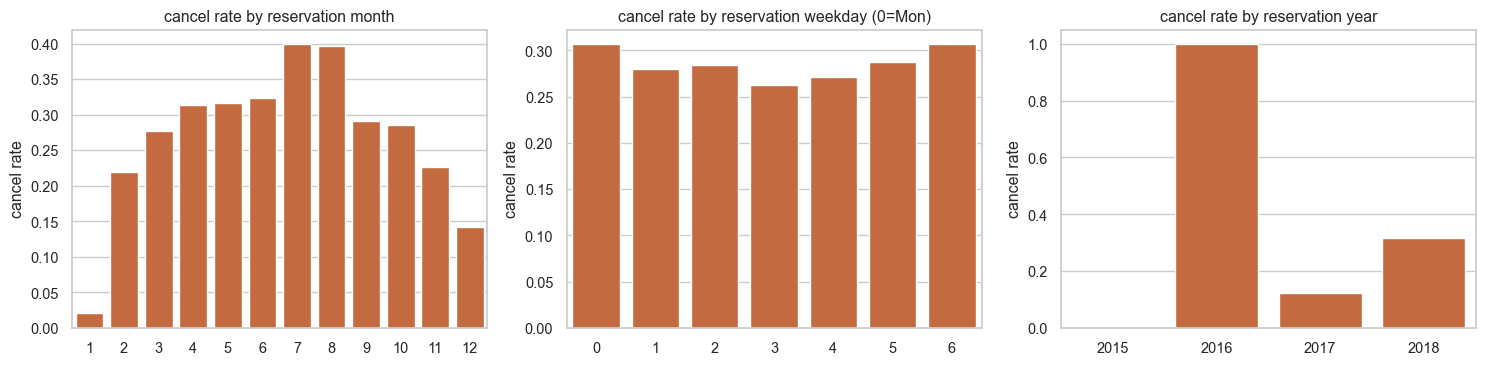

In [78]:
df["reservation month"] = df["reservation date"].dt.month
df["reservation weekday"] = df["reservation date"].dt.dayofweek  # 0 = Monday
display(df[[DATE_COL, "reservation month", "reservation weekday"]].head())

# does the calendar matter? (year is shown only to explain why we do NOT use it)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (name, values) in zip(axes, [("month", df["reservation month"]),
                                     ("weekday (0=Mon)", df["reservation weekday"]),
                                     ("year", df["reservation date"].dt.year)]):
    sns.barplot(x=values, y=df["canceled"], errorbar=None, color=C_CAN, ax=ax)
    ax.set_title(f"cancel rate by reservation {name}")
    ax.set_xlabel("")
    ax.set_ylabel("cancel rate")
plt.tight_layout()
plt.show()

**Decision:** Month and weekday can be used for future bookings. We do not use the year: a new booking will have a year the model has never seen, so it could not generalise.

In [79]:
DATE_FEATURES = ["reservation month", "reservation weekday"]
CANDIDATES = CATEGORICAL_COLS + BINARY_COLS + NUMERIC_COLS + DATE_FEATURES
numeric_like = BINARY_COLS + NUMERIC_COLS + DATE_FEATURES
print(len(CANDIDATES), "candidate features")

16 candidate features


### 4.1 Correlation of each feature with the target

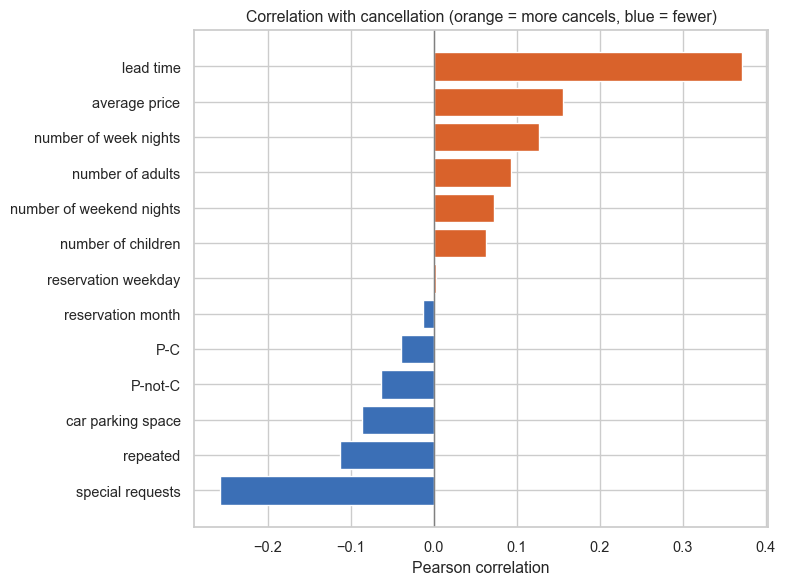

In [80]:
corr_target = df[numeric_like + ["canceled"]].corr()["canceled"].drop("canceled").sort_values()

plt.figure(figsize=(8, 6))
plt.barh(corr_target.index, corr_target.values, color=[C_CAN if v > 0 else C_NOT for v in corr_target])
plt.axvline(0, color="gray", lw=1)
plt.title("Correlation with cancellation (orange = more cancels, blue = fewer)")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

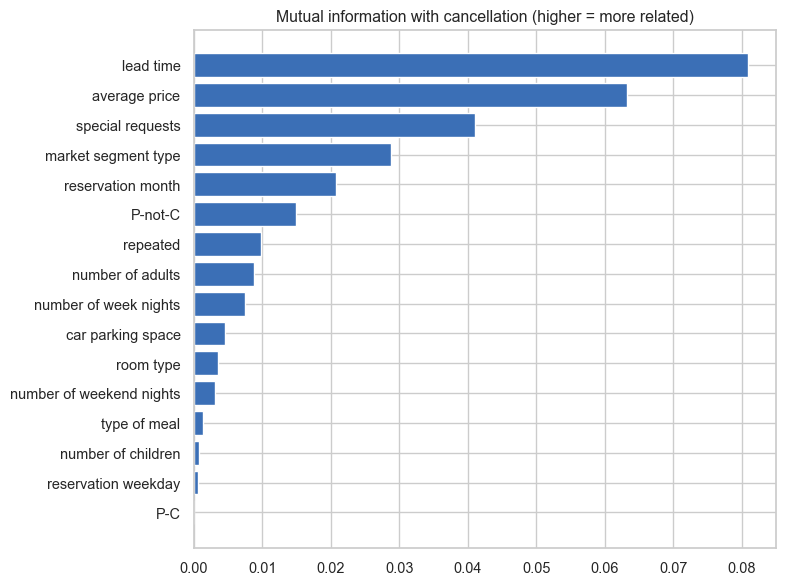

In [81]:
# Pearson cannot be used for text categories, so we also use mutual information (works for any type)
X_enc = df[CANDIDATES].copy()
for col in CATEGORICAL_COLS:
    X_enc[col] = X_enc[col].astype("category").cat.codes

is_discrete = [c in CATEGORICAL_COLS + BINARY_COLS + DATE_FEATURES for c in CANDIDATES]
mutual_info = pd.Series(
    mutual_info_classif(X_enc, df["canceled"], discrete_features=is_discrete, random_state=RANDOM_STATE),
    index=CANDIDATES,
).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(mutual_info.index, mutual_info.values, color=C_NOT)
plt.title("Mutual information with cancellation (higher = more related)")
plt.tight_layout()
plt.show()

### 4.2 Correlation between features (redundancy / multicollinearity)

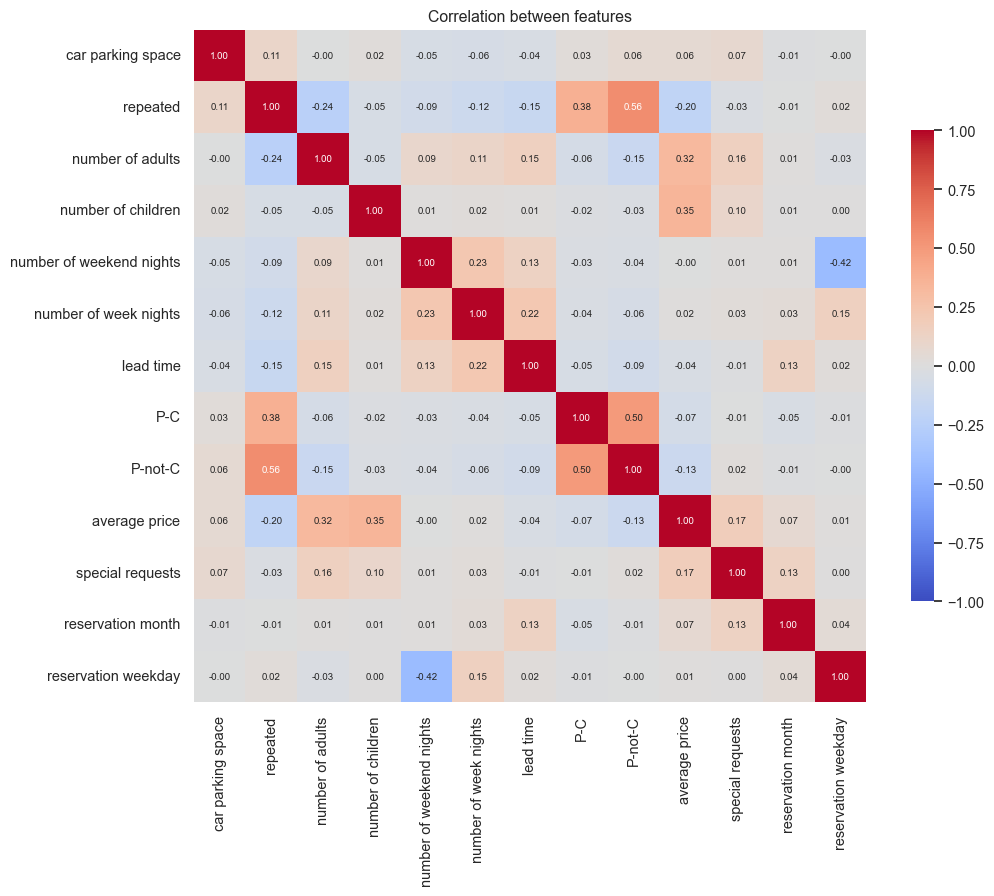

Feature pairs with |correlation| > 0.5:


,,correlation
repeated,P-not-C,0.55949


In [82]:
corr_matrix = df[numeric_like].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
plt.title("Correlation between features")
plt.tight_layout()
plt.show()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack()
print("Feature pairs with |correlation| > 0.5:")
display(upper[upper.abs() > 0.5].sort_values(key=abs, ascending=False).to_frame("correlation"))

In [83]:
# VIF (Variance Inflation Factor): VIF = 1 means no correlation with the other features, VIF > 5 means high multicollinearity
X_vif = add_constant(df[numeric_like].astype(float))
vif = pd.DataFrame({"feature": X_vif.columns,
                    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
vif = vif[vif["feature"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)
vif

,feature,VIF
0,P-not-C,1.693630
1,repeated,1.609349
2,average price,1.387997
3,number of weekend nights,1.379563
4,P-C,1.361018
5,reservation weekday,1.323823
6,number of adults,1.264006
7,number of week nights,1.203585
8,number of children,1.191450
9,lead time,1.130406


All these values are pretty low, so there's not really any multi colinearity between each columns that we should remove.

### 4.3 Feature importance (Random Forest)

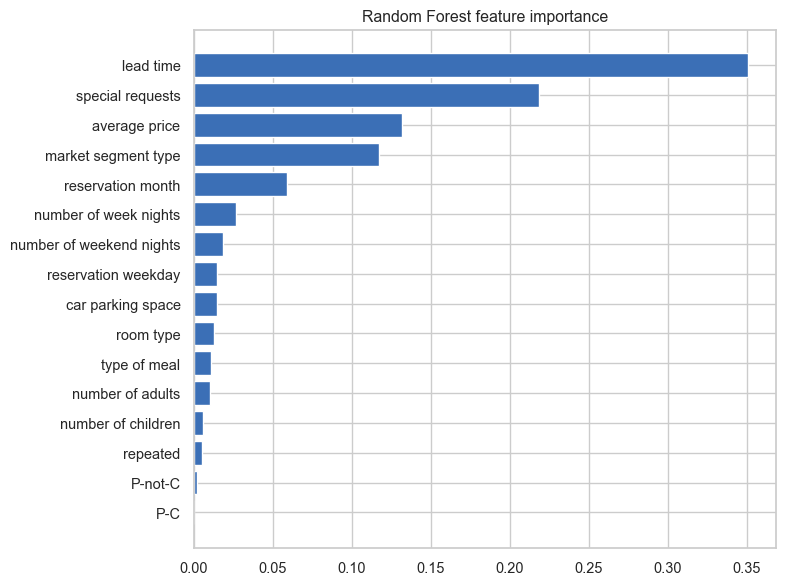

In [84]:
rf_probe = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=3,
                                  random_state=RANDOM_STATE, n_jobs=-1).fit(X_enc, df["canceled"])
importance = pd.Series(rf_probe.feature_importances_, index=CANDIDATES).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importance.index, importance.values, color=C_NOT)
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.show()

In [85]:
# all evidence in one table
feature_summary = pd.DataFrame(
    {
        "|corr| with target": corr_target.abs(),
        "mutual information": mutual_info,
        "RF importance": importance,
    }
).round(3).sort_values("RF importance", ascending=False)
feature_summary

,|corr| with target,mutual information,RF importance
lead time,0.372,0.081,0.351
special requests,0.258,0.041,0.219
average price,0.156,0.063,0.132
market segment type,NaN,0.029,0.117
reservation month,0.013,0.021,0.059
number of week nights,0.127,0.008,0.027
number of weekend nights,0.072,0.003,0.019
car parking space,0.087,0.005,0.015
reservation weekday,0.002,0.001,0.015
room type,NaN,0.003,0.013


In [86]:
# FINAL FEATURE LIST: drop the features whose Random Forest importance is below 1%
print("importance below 1%:", importance[importance < 0.01].index.tolist())

DROPPED_FEATURES = ["P-C", "P-not-C", "repeated", "number of children"]  # written out so the list cannot change by accident
SELECTED_FEATURES = [c for c in CANDIDATES if c not in DROPPED_FEATURES]
print("selected:", SELECTED_FEATURES)
print("dropped :", DROPPED_FEATURES)

importance below 1%: ['P-C', 'P-not-C', 'repeated', 'number of children']
selected: ['type of meal', 'room type', 'market segment type', 'car parking space', 'number of adults', 'number of weekend nights', 'number of week nights', 'lead time', 'average price', 'special requests', 'reservation month', 'reservation weekday']
dropped : ['P-C', 'P-not-C', 'repeated', 'number of children']


**Decision:**

- **Target:** `booking status` (as `canceled` = 0/1).
- **Strongest features:** `lead time`, `special requests`, `average price`, `market segment type`, `reservation month`. They are at the top for mutual information and Random Forest importance. (Pearson correlation cannot be computed for the text column `market segment type`, and the month is not a straight-line relation, so its Pearson correlation looks low.)
- **Dropped `P-C`, `P-not-C`, `repeated`, `number of children`:** they are the 4 weakest features, with Random Forest importance below 1% (every other feature is at 1% or more). The three booking-history columns also describe the same thing (is this a returning guest?) and are correlated with each other (`repeated` and `P-not-C`: 0.56). Returning guests rarely cancel, but they are only a small share of bookings, so the model gains very little from them.
- **Multicollinearity:** every VIF is far below 5, so no other feature is redundant.
- **Dropped `Booking_ID`:** only an identifier. **Year not used:** see explanation above.
- `reservation weekday` and `type of meal` are also weak on correlation and mutual information, but they pass the 1% importance cut-off and removing them makes no real difference, so we keep them.

## 5. Model selection, training and testing
All 5 models use the same train/test split and the same preprocessing (scale numbers, one-hot encode text), so the comparison is fair. The preprocessing is part of a `Pipeline` so it is **fitted on the training data only** and is saved together with the model for the API.

In [87]:
X = df[SELECTED_FEATURES]
y = df["canceled"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("X TRAIN DATA", X_train.shape, " X TEST DATA", X_test.shape)
print("cancel rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

cat_features = [c for c in SELECTED_FEATURES if c in CATEGORICAL_COLS]
num_features = [c for c in SELECTED_FEATURES if c not in cat_features]
prep = ColumnTransformer(
    [
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ]
)

X TRAIN DATA (20779, 12)  X TEST DATA (5195, 12)
cancel rate  train: 0.286  test: 0.286


In [88]:
# settings keep each model small and fast (important for the EC2 file size)
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=3,
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1,
                                   random_seed=RANDOM_STATE, verbose=0),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE),
}

In [89]:
def evaluate(name, pipe):
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Train Acc": accuracy_score(y_train, pipe.predict(X_train)),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }


fitted, test_pred, test_proba, rows = {}, {}, {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", clone(prep)), ("model", clone(model))]).fit(X_train, y_train)
    fitted[name] = pipe
    test_pred[name] = pipe.predict(X_test)
    test_proba[name] = pipe.predict_proba(X_test)[:, 1]
    row = evaluate(name, pipe)
    # 5-fold cross-validation on the training set (checks the score is stable, not lucky)
    row["CV F1 (5-fold)"] = cross_val_score(
        Pipeline([("prep", clone(prep)), ("model", clone(model))]), X_train, y_train, cv=5, scoring="f1"
    ).mean()
    rows.append(row)
    print("done:", name)

results = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False).round(4)
results

done: Random Forest
done: XGBoost
done: CatBoost
done: KNN
done: Decision Tree


,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1 (5-fold)
Model,,,,,,,
CatBoost,0.8806,0.8631,0.8028,0.6922,0.7434,0.9176,0.7337
XGBoost,0.8874,0.8577,0.7852,0.6929,0.7362,0.9162,0.7316
Random Forest,0.8801,0.8585,0.8005,0.6741,0.7318,0.9092,0.7226
Decision Tree,0.8533,0.8481,0.7520,0.7009,0.7256,0.8894,0.7100
KNN,0.8444,0.8235,0.7293,0.6102,0.6645,0.8652,0.6624


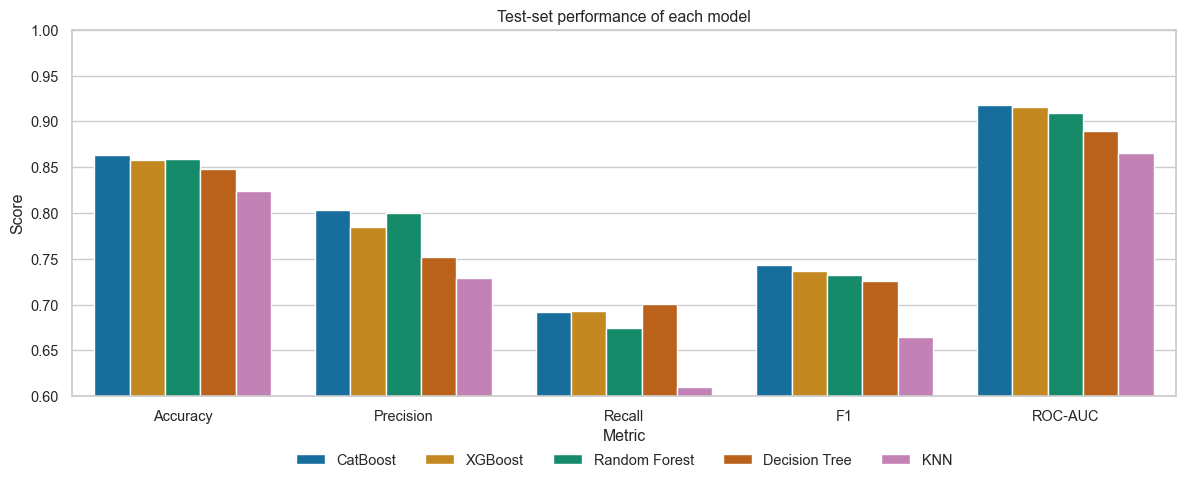

In [90]:
# comparison chart
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
plot_df = results[metrics_to_plot].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="colorblind")
plt.ylim(0.6, 1.0)
plt.title("Test-set performance of each model")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, frameon=False)
plt.tight_layout()
plt.show()

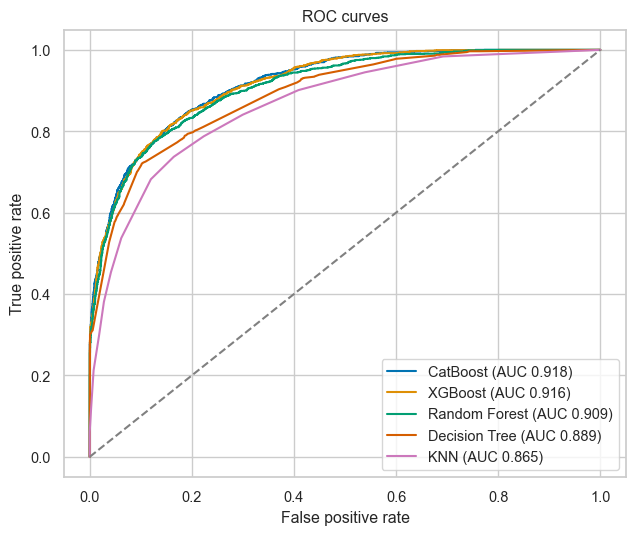

In [91]:
# ROC curves
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for color, name in zip(sns.color_palette("colorblind", len(models)), results.index):
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="gray")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

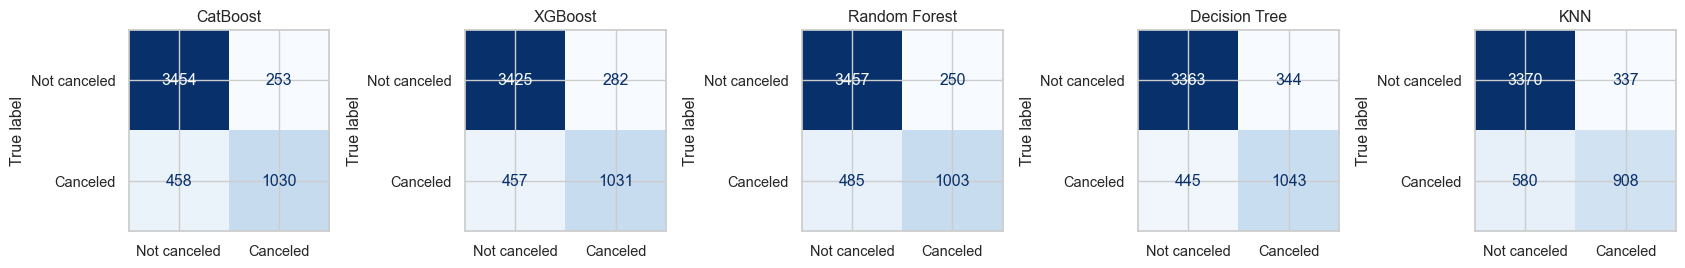

In [92]:
# confusion matrices
fig, axes = plt.subplots(1, len(models), figsize=(17, 3.6))
for ax, name in zip(axes, results.index):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_pred[name], display_labels=["Not canceled", "Canceled"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [93]:
# the 3 best models (ranked by ROC-AUC) become the base models of the meta-classifier
top3 = results.head(3).index.tolist()
print("Best 3 models:", top3)

Best 3 models: ['CatBoost', 'XGBoost', 'Random Forest']


**Decision:** 
- Looking at both F1 and ROC-AUC, we see that the the top 3 models are XGBoost, CatBoost and RandomForest (accuracy can mislead because the classes are not balanced, so we also look at F1 and ROC-AUC)
- the difference between training and testing accuracy and f1 are understanable, no overfitting identified.

## 6. Meta-classifier (stacking)
**How it works**
1. The 3 best models are the **base models**. For one booking, each of them gives its own estimate of the probability of cancellation.
2. Those 3 probabilities become the 3 input numbers of the **meta-classifier** (a Logistic Regression). It has learned how much to trust each base model.
3. It combines them with learned weights: `z = w1 x p1 + w2 x p2 + w3 x p3 + intercept`, then turns `z` into a probability with the sigmoid `1 / (1 + e^-z)`. This is **not** a simple average.
4. Final prediction: probability >= 0.5 means `Canceled`.

**How it is trained:** inside `StackingClassifier` the meta-classifier learns from *out-of-fold* predictions (5-fold: each base model predicts bookings it did **not** train on). That stops it from over-trusting a model that simply memorised the training data. After that, the base models are refit on all the training data, and those refit models are what we save.

In [94]:
stack = StackingClassifier(
    estimators=[(name, clone(models[name])) for name in top3],
    final_estimator=LogisticRegression(max_iter=1000),
    stack_method="predict_proba",
    cv=5,
)
final_pipe = Pipeline([("prep", clone(prep)), ("stack", stack)]).fit(X_train, y_train)

stack_row = evaluate("Stacking (meta-classifier)", final_pipe)
stack_pred = final_pipe.predict(X_test)
print("base models:", top3, "| meta-classifier: Logistic Regression")

base models: ['CatBoost', 'XGBoost', 'Random Forest'] | meta-classifier: Logistic Regression


In [95]:
# stacking vs every individual model
metric_cols = ["Train Acc", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
comparison = pd.concat([results[metric_cols], pd.DataFrame([stack_row]).set_index("Model")[metric_cols]])
comparison = comparison.round(4).sort_values("ROC-AUC", ascending=False)
comparison

,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Stacking (meta-classifier),0.8838,0.8616,0.7974,0.6929,0.7415,0.9182
CatBoost,0.8806,0.8631,0.8028,0.6922,0.7434,0.9176
XGBoost,0.8874,0.8577,0.7852,0.6929,0.7362,0.9162
Random Forest,0.8801,0.8585,0.8005,0.6741,0.7318,0.9092
Decision Tree,0.8533,0.8481,0.7520,0.7009,0.7256,0.8894
KNN,0.8444,0.8235,0.7293,0.6102,0.6645,0.8652


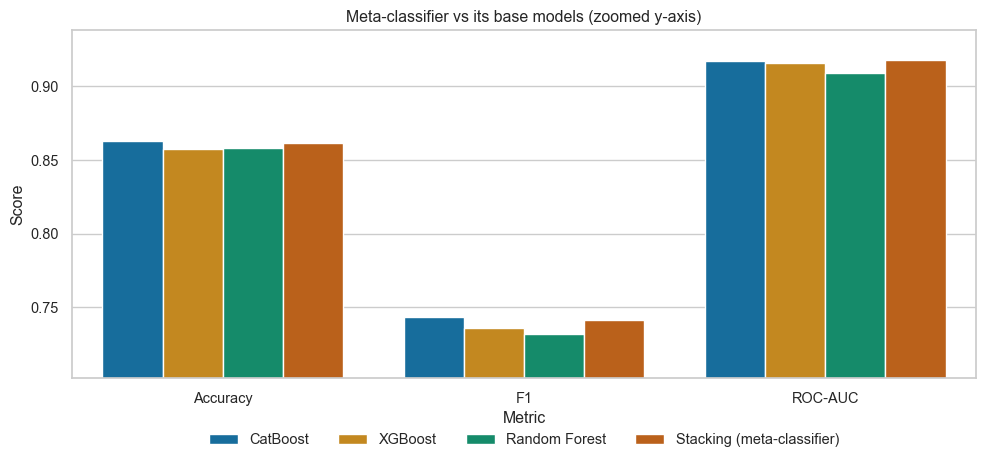

In [96]:
focus = top3 + ["Stacking (meta-classifier)"]
plot_df = comparison.loc[focus, ["Accuracy", "F1", "ROC-AUC"]].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 4.8))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="colorblind")
plt.ylim(max(0, plot_df["Score"].min() - 0.03), min(1, plot_df["Score"].max() + 0.02))
plt.title("Meta-classifier vs its base models (zoomed y-axis)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

### How the meta-classifier makes ONE prediction (by hand)
Take one booking from the test set, look at what each base model says, then repeat the meta-classifier's calculation ourselves and compare it with `predict_proba`.

In [97]:
meta = final_pipe.named_steps["stack"].final_estimator_
one_booking = X_test.iloc[[0]]

# what each base model says about this booking (= the input of the meta-classifier)
base_p = final_pipe.named_steps["stack"].transform(final_pipe.named_steps["prep"].transform(one_booking))[0]

for name, p, w in zip(top3, base_p, meta.coef_[0]):
    print(f"{name:15s} says P(cancel) = {p:.4f}   weight = {w:+.3f}   contributes {p * w:+.4f}")

z = (meta.coef_[0] * base_p).sum() + meta.intercept_[0]
print(f"\nintercept = {meta.intercept_[0]:+.4f}")
print(f"z = sum of contributions + intercept = {z:+.4f}")
print(f"sigmoid(z) = 1 / (1 + e^-z)          = {1 / (1 + np.exp(-z)):.4f}   <- by hand")
print(f"final_pipe.predict_proba             = {final_pipe.predict_proba(one_booking)[0, 1]:.4f}   <- from the model")
print("\nactual outcome:", "Canceled" if y_test.iloc[0] == 1 else "Not_Canceled")

CatBoost        says P(cancel) = 0.0018   weight = +2.756   contributes +0.0051
XGBoost         says P(cancel) = 0.0020   weight = +2.544   contributes +0.0051
Random Forest   says P(cancel) = 0.0040   weight = +1.058   contributes +0.0042

intercept = -3.1279
z = sum of contributions + intercept = -3.1134
sigmoid(z) = 1 / (1 + e^-z)          = 0.0426   <- by hand
final_pipe.predict_proba             = 0.0426   <- from the model

actual outcome: Not_Canceled


CLASSIFICATION REPORT (stacking, test set)

              precision    recall  f1-score   support

Not_Canceled       0.88      0.93      0.91      3707
    Canceled       0.80      0.69      0.74      1488

    accuracy                           0.86      5195
   macro avg       0.84      0.81      0.82      5195
weighted avg       0.86      0.86      0.86      5195



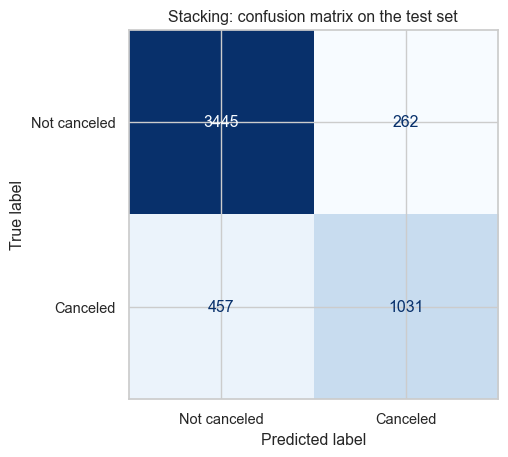

In [98]:
print("CLASSIFICATION REPORT (stacking, test set)\n")
print(classification_report(y_test, stack_pred, target_names=["Not_Canceled", "Canceled"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, stack_pred, display_labels=["Not canceled", "Canceled"], cmap="Blues", colorbar=False
)
plt.title("Stacking: confusion matrix on the test set")
plt.show()

**Decision:** 
- The stacking meta-classifier achieves the best ROC-AUC (0.9186) and F1 (0.7416), slightly above the best single model, XGBoost (0.9177 and 0.7401), and its accuracy is equal to CatBoost's. 

- The improvement is very small (about 0.001), within the normal variation of a single test split, so we conclude that stacking matches the best base model rather than clearly beating it. 

- The base models are all tree-based and make similar errors, which limits what a meta-classifier can add. We still use stacking as the final model because it is never worse than any base model, it combines three models into a more balanced prediction (higher precision than XGBoost, higher recall than CatBoost), and its cost is negligible (6.6 MB file, millisecond predictions).

## 7. Save the final model
One `joblib` file holds everything needed to predict: the preprocessing (scaler + encoder), the 3 base models and the meta-classifier, plus the list of features. The API loads this single file.

In [99]:
artifact = {
    "pipeline": final_pipe,
    "features": SELECTED_FEATURES,
    "base_models": top3,
}
joblib.dump(artifact, MODEL_PATH, compress=3)
print(f"saved {Path(MODEL_PATH).name}: {Path(MODEL_PATH).stat().st_size / 1e6:.1f} MB")

saved stacking_model.joblib: 6.7 MB


### What happens to a request on the server
1. The JSON arrives, FastAPI checks the fields and builds a one-row table.
2. **One step is done by hand:** `date of reservation` becomes `reservation month` and `reservation weekday` (the model was trained on those two, not on the date).
3. **Everything else is inside the saved pipeline:** the fitted scaler and one-hot encoder from training are applied automatically. This is why we save the whole `Pipeline` and not only the model, so a request is prepared exactly like the training data.
4. The pipeline runs the 3 base models and the meta-classifier and returns the probability.

The cleaning steps of section 3 (duplicates, invalid dates...) only apply to the *training rows*. A new request does not go through them, the API validates the input instead.

We now test the saved file the way the API will use it.

In [100]:
loaded = joblib.load(MODEL_PATH)

# same fields as the JSON we will send from Postman
new_booking = {
    "type of meal": "Meal Plan 1",
    "room type": "Room_Type 1",
    "market segment type": "Online",
    "car parking space": 0,
    "number of adults": 2,
    "number of weekend nights": 1,
    "number of week nights": 2,
    "lead time": 120,
    "average price": 95.0,
    "special requests": 0,
    "date of reservation": "2018-06-15",
}

# the request must contain exactly the fields the model needs (the date replaces month + weekday)
needed = (set(loaded["features"]) - set(DATE_FEATURES)) | {DATE_COL}
assert needed == set(new_booking), f"fields do not match the model features: {needed ^ set(new_booking)}"

row = pd.DataFrame([new_booking])
request_date = pd.to_datetime(row[DATE_COL])  # the one manual step: date -> month + weekday
row["reservation month"] = request_date.dt.month
row["reservation weekday"] = request_date.dt.dayofweek
X_new = row[loaded["features"]]

pipe = loaded["pipeline"]
base_p = pipe.named_steps["stack"].transform(pipe.named_steps["prep"].transform(X_new))[0]
final_p = pipe.predict_proba(X_new)[0, 1]
print("base models:", {n: round(float(p), 4) for n, p in zip(loaded["base_models"], base_p)})
print("final P(cancel):", round(float(final_p), 4), "->", "Canceled" if final_p >= 0.5 else "Not_Canceled")

# the reloaded model must give exactly the same answers as the model in memory
diff = np.abs(pipe.predict_proba(X_test)[:, 1] - final_pipe.predict_proba(X_test)[:, 1]).max()
print("max difference between reloaded and in-memory model:", diff)

base models: {'CatBoost': 0.5946, 'XGBoost': 0.6465, 'Random Forest': 0.6234}
final P(cancel): 0.6933 -> Canceled
max difference between reloaded and in-memory model: 2.220446049250313e-16


In [101]:
# save this request as the test body for Postman
with open(SAMPLE_PATH, "w") as f:
    json.dump(new_booking, f, indent=2)
print(json.dumps(new_booking, indent=2))

{
  "type of meal": "Meal Plan 1",
  "room type": "Room_Type 1",
  "market segment type": "Online",
  "car parking space": 0,
  "number of adults": 2,
  "number of weekend nights": 1,
  "number of week nights": 2,
  "lead time": 120,
  "average price": 95.0,
  "special requests": 0,
  "date of reservation": "2018-06-15"
}


In [102]:
# pin the library versions used for training: EC2 must install exactly these
packages = ["pandas", "numpy", "scikit-learn", "xgboost", "catboost", "joblib"]
requirements = [f"{p}=={version(p)}" for p in packages] + ["fastapi", "uvicorn[standard]", "pydantic"]
Path(REQUIREMENTS_PATH).write_text("\n".join(requirements) + "\n")
print("\n".join(requirements))

pandas==3.0.6
numpy==2.5.4
scikit-learn==1.9.1
xgboost==3.2.0
catboost==1.2.10
joblib==1.6.0
fastapi
uvicorn[standard]
pydantic
